# 26. Validación temporal actualizada y reentrenamiento en operación

Se conserva el modelo del cuaderno 19: boosting sin clima, grupos H1–H2/H3–H5 y corrección de teoría o Media4. No se buscan nuevos parámetros. Esta ejecución **local y retrospectiva** usa una copia identificada de las fuentes; no publica pronósticos ni escribe en SQL. La consulta de WebFlor y la persistencia SQL son procesos separados: este cuaderno puede repetirse con los archivos ya archivados, sin volver a consultar la empresa.

Respondemos tres preguntas: ¿los datos nuevos están incorporados?, ¿cómo se comporta la configuración fija después de S36?, ¿qué diferencia hay entre conservar un ajuste congelado y reentrenarlo mensualmente? No equiparamos esta simulación con un pronóstico emitido antes de la cosecha.

Orden: fuentes → separación temporal → modelo fijado → entrenamiento/prueba → comparación nominal con ingeniero → diagnóstico y pronóstico más reciente → conclusiones y operación.

In [1]:
from pathlib import Path
import sys,json,hashlib,joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'plataforma_gaitana/backend/app/model19.py').exists())
sys.path.insert(0,str(ROOT/'plataforma_gaitana/backend'))
from app.model19 import dataset,build_model,CATEGORIES,MEMORY,WEATHER,PARAMS
from app.history_eval import engineer_archive
from app.data import KEY
SOURCE=ROOT/'plataforma_gaitana/storage/datasets/evaluacion_local_20261028'
OUT=ROOT/'Datos_analiticos_proyecto/validacion_temporal_20261028'
OUT.mkdir(exist_ok=True);(OUT/'figuras').mkdir(exist_ok=True)
AS_OF=pd.Timestamp('2026-10-28')
NEW_START=pd.Timestamp('2026-09-07')
FROZEN_CUT=pd.Timestamp('2026-08-03')
MANIFEST=json.loads((SOURCE/'manifest.json').read_text(encoding='utf-8'))
assert MANIFEST['offline'] and MANIFEST['state'] in ['validado_local','validado','activo']
assert len(set(MANIFEST['completed_stages']))==11
print('Copia local:',MANIFEST['id'],'· fecha de evaluación:',AS_OF.date())
print('Parámetros conservados:',PARAMS)

Copia local: evaluacion_local_20261028 · fecha de evaluación: 2026-10-28
Parámetros conservados: {'learning_rate': 0.08, 'max_iter': 80, 'max_leaf_nodes': 15, 'min_samples_leaf': 40, 'l2_regularization': 1.0, 'early_stopping': False, 'random_state': 42}


## 1. Qué datos usamos y qué validamos

La base persistida anterior llega al 24/10. Se incorporan los Excel recibidos de clima y plano S42 y la descarga WebFlor ya archivada hasta el 27/10. La ventana WebFlor sustituye sólo su rango reciente, preservando el histórico anterior y los movimientos repetidos legítimos. No se consulta la empresa en esta corrida.

Se comprueban hashes, columnas y cantidades mediante el ETL canónico. La producción actualizada de una semana en curso **no la convierte en objetivo evaluable**: evaluamos sólo semanas terminadas antes del 28/10. Los estimados nominales del ingeniero se usan exclusivamente como referencia, nunca como entradas.

In [2]:
source_rows=[]
for name,item in MANIFEST['outputs'].items():
    path=SOURCE/'Datos_analiticos_proyecto'/f'{name}.parquet'
    h=hashlib.sha256(path.read_bytes()).hexdigest()
    assert h==item['sha256'],name
    source_rows.append({'fuente':name,'registros':item['rows'],'desde':item['since'],'hasta':item['through'],'sha256':h})
sources=pd.DataFrame(source_rows);sources.to_csv(OUT/'fuentes_validadas.csv',index=False)
display(sources.drop(columns='sha256'))
df,daily,extra=dataset(SOURCE)
assert not df.duplicated(KEY+['origen','horizonte']).any()
assert df.horizonte.between(1,5).all()
weekly=pd.read_parquet(SOURCE/'Datos_analiticos_proyecto/modelo_con_proyecciones_teoricas/produccion_clima_semanal.parquet')
actual=pd.read_parquet(SOURCE/'Datos_analiticos_proyecto/produccion_real_limpio.parquet',columns=['finca','semana_inicio','tallos'])
assert weekly.tallos_reales.sum()==actual.loc[actual.finca.eq('GAITANA')&actual.semana_inicio.ge('2021-01-01'),'tallos'].sum()
assert actual.tallos.notna().all() and actual.tallos.ge(0).all()
farm_audit=actual.groupby('finca').agg(registros=('tallos','size'),tallos=('tallos','sum')).reset_index()
farm_audit['en_modelo_semanal']=farm_audit.finca.eq('GAITANA')
farm_audit.to_csv(OUT/'auditoria_fincas.csv',index=False)
display(farm_audit)
other=farm_audit.loc[~farm_audit.finca.isin(['GAITANA','ARABELLA'])]
print('Etiquetas de finca fuera del alcance validado, conservadas en la fuente:',int(other.registros.sum()),'registros /',int(other.tallos.sum()),'tallos.')
print('El modelo usa GAITANA; no se reasignan etiquetas desconocidas ni se eliminan movimientos repetidos legítimos.')
engineer=engineer_archive(SOURCE,pd.read_parquet,KEY)
assert not engineer.duplicated(KEY+['origen','semana_objetivo','horizonte']).any()
closed=df.y.notna()&(df.semana_objetivo+pd.Timedelta(days=7)).le(AS_OF)
eligible=df.admisible_modelo&closed
universe=df.loc[eligible].copy()
print('Última semana objetivo cerrada con real:',universe.semana_objetivo.max().date())

,fuente,registros,desde,hasta
0,produccion_real_limpio,6550639,2021-01-04,2026-10-27
1,clima_limpio,194558,2021-01-01,2026-10-23
2,planos_siembra_limpio,3356921,2021-01-04,2026-10-12
3,curvas_variedad_limpio,562987,2012-12-31,2026-09-21
4,estimados_semanales_limpio,181301,2023-01-02,2026-11-09


,finca,registros,tallos,en_modelo_semanal
0,<,1,70,False
1,ARABELLA,1773411,128211280,False
2,GAITANA,4777225,338568100,True
3,GAITANA PPTO,2,160,False


Etiquetas de finca fuera del alcance validado, conservadas en la fuente: 3 registros / 230 tallos.
El modelo usa GAITANA; no se reasignan etiquetas desconocidas ni se eliminan movimientos repetidos legítimos.


Última semana objetivo cerrada con real: 2026-10-19


## 2. Train, validación y test: tres funciones diferentes

* **Train de cada ajuste:** casos admisibles con objetivo observado y `semana_objetivo + 7 días <= corte`. La codificación y la imputación se ajustan sólo con esas filas.
* **Validación de selección:** noviembre–diciembre de 2025, objetivos cerrados antes del 01/01/2026. La elección Sin_clima ya fue tomada en 19; aquí se comprueba, no se vuelve a seleccionar.
* **Evaluación retrospectiva de referencia:** semanas de 2026 hasta S36. Se conserva el archivo original y se informa aparte la reconstrucción con las fuentes actuales.
* **Extensión posterior:** semanas objetivo desde S37, con semanas completas disponibles. Incluye los pronósticos de esas semanas que se habrían emitido en orígenes anteriores; se mantienen los horizontes originales. Dos protocolos sobre los mismos casos: actualización mensual del 19 y ajuste congelado al 03/08, último corte de la referencia original. El congelado no incorpora objetivos posteriores a ese corte; el mensual sólo incorpora los que ya cerraron antes de cada nuevo corte.

No hay reparto aleatorio 80/20. El porcentaje por ajuste depende de los años de historia y del tamaño del bloque futuro. **No se suman los train repetidos** para anunciar un porcentaje global. Una semana evaluada puede entrenar un ajuste posterior sin que su respuesta haya sido conocida por el ajuste que la predijo.

La extensión también es retrospectiva: septiembre fue revisado en experimentos anteriores. Octubre se informa como comprobación adicional sin tuneo en esta corrida, no como evidencia de una publicación anticipada. Ninguna de estas etiquetas certifica por sí sola que cada archivo histórico se hubiera publicado a tiempo.

In [3]:
common=CATEGORIES+['horizonte','semana_seno','semana_coseno']+MEMORY+WEATHER
xb=common+daily+extra
xt=common+['teoria_modelo','antiguedad_curva','desviacion_reciente_teoria']+daily+extra
excluded=WEATHER+[c for c in daily if any(v in c for v in ['temperatura','humedad','radiacion'])]
xb=[c for c in xb if c not in excluded];xt=[c for c in xt if c not in excluded]
assert 'ingeniero' not in xb+xt and 'y' not in xb+xt
assert not any(any(w in c for w in ['temperatura','humedad','radiacion']) for c in xb+xt)
pd.DataFrame([{'ruta':'Media4','variable':c} for c in xb]+[{'ruta':'Teoría','variable':c} for c in xt]).to_csv(OUT/'variables_modelo.csv',index=False)
def score(y,p):
    y=np.asarray(y,dtype=float);p=np.asarray(p,dtype=float)
    ok=np.isfinite(y)&np.isfinite(p);y=y[ok];p=p[ok];e=p-y;den=y.sum();positive=y>0
    return {'casos':len(y),'MAE':float(np.abs(e).mean()) if len(y) else None,
        'RMSE':float(np.sqrt(np.square(e).mean())) if len(y) else None,
        'WAPE':float(100*np.abs(e).sum()/den) if den else None,
        'sesgo_pct':float(100*e.sum()/den) if den else None,'sesgo_tallos':float(e.sum()),
        'MAPE_positivos':float(100*np.mean(np.abs(e[positive])/y[positive])) if positive.any() else None,
        'dentro_8_pct':float(100*np.mean(np.abs(e[positive])/y[positive]<=.08)) if positive.any() else None,
        'real_tallos':float(den),'reales_positivos':int(positive.sum())}
models={};fit_controls=[];train_scores=[]
stable_outputs={name:{k:v for k,v in item.items() if k!='sql_dataset_id'} for name,item in MANIFEST['outputs'].items()}
cache_signature=hashlib.sha256(json.dumps({'outputs':stable_outputs,'params':PARAMS,'xb':xb,'xt':xt,
    'adapter':hashlib.sha256((ROOT/'plataforma_gaitana/backend/app/model19.py').read_bytes()).hexdigest()},sort_keys=True).encode()).hexdigest()[:16]
model_folder=OUT/'modelos';model_folder.mkdir(exist_ok=True)
def train_at(cut):
    cut=pd.Timestamp(cut)
    if cut in models:return models[cut]
    tr=df.loc[df.admisible_modelo&df.y.notna()&(df.semana_objetivo+pd.Timedelta(days=7)).le(cut)].copy()
    assert len(tr) and (tr.semana_objetivo+pd.Timedelta(days=7)).le(cut).all()
    cache=model_folder/f'{cache_signature}_{cut.date()}.joblib'
    fitted=joblib.load(cache) if cache.exists() else {}
    with threadpool_limits(limits=2):
        for group,g in tr.groupby('grupo_h'):
            if group in fitted:continue
            fallback=build_model(xb).fit(g[xb],g.y-g.media_4)
            tc=g.loc[g.curva_completa]
            theory=build_model(xt).fit(tc[xt],tc.y-tc.teoria_modelo) if len(tc)>=40 else None
            fitted[group]=(fallback,theory)
    if not cache.exists():joblib.dump(fitted,cache)
    models[cut]=fitted
    fit_controls.append({'corte':cut,'train_casos':len(tr),'train_origen_desde':tr.origen.min(),
        'train_objetivo_desde':tr.semana_objetivo.min(),'train_objetivo_hasta':tr.semana_objetivo.max(),
        'train_ultimo_cierre':tr.semana_objetivo.max()+pd.Timedelta(days=7),
        'train_semanas_objetivo':tr.semana_objetivo.nunique()})
    p,_=predict(fitted,tr)
    train_scores.append({'corte':cut,'particion':'train',**score(tr.y,p)})
    if cut==max(models):
        saved=tr[KEY+['origen','semana_objetivo','horizonte','y']].copy()
        saved['prediccion']=p;saved['corte_entrenamiento']=cut
        saved.to_parquet(OUT/'predicciones_train_ultimo_ajuste.parquet',index=False)
    print('Ajustado:',cut.date(),'· train:',len(tr),flush=True)
    return fitted
def predict(fitted,te):
    p=pd.Series(index=te.index,dtype=float);route=pd.Series('memoria_4_semanas',index=te.index)
    with threadpool_limits(limits=2):
        for group,g in te.groupby('grupo_h'):
            fallback,theory=fitted[group]
            p.loc[g.index]=np.maximum(0,g.media_4+fallback.predict(g[xb]))
            tc=g.loc[g.curva_completa]
            if theory is not None and len(tc):
                p.loc[tc.index]=np.maximum(0,tc.teoria_modelo+theory.predict(tc[xt]));route.loc[tc.index]='teoria_corregida'
    assert p.notna().all() and np.isfinite(p).all()
    return p,route
def rolling(te):
    results=[]
    for month,g in te.groupby(te.origen.dt.to_period('M')):
        cut=df.loc[df.origen.dt.to_period('M').eq(month),'origen'].min()
        assert cut<=g.origen.min()
        p,route=predict(train_at(cut),g)
        z=g[KEY+['origen','semana_objetivo','horizonte','y','media_4']].copy()
        z['prediccion']=p;z['ruta']=route;z['corte_entrenamiento']=cut;results.append(z)
    return pd.concat(results,ignore_index=True)

## 3. Ejecución sin cambiar la selección

Se guardan los pronósticos individuales y los cortes: permiten recalcular las métricas y comprobar que ninguna semana objetivo de train termina después del corte. Los grupos y las rutas conservan exactamente la parametrización de 19. La alternativa congelada cambia únicamente la política de actualización, no la arquitectura ni los hiperparámetros.

In [4]:
validation_mask=universe.origen.ge('2025-11-03')&(universe.semana_objetivo+pd.Timedelta(days=7)).le(pd.Timestamp('2026-01-01'))
val=rolling(universe.loc[validation_mask])
val.to_parquet(OUT/'predicciones_validacion_2025.parquet',index=False)
test_mask=universe.origen.dt.isocalendar().year.eq(2026)&universe.semana_objetivo.dt.isocalendar().year.eq(2026)
test=rolling(universe.loc[test_mask])
test['modelo']='19_mensual_sin_clima'
extension=test.loc[test.semana_objetivo.ge(NEW_START)].copy()
assert len(extension)
frozen_input=universe.loc[test_mask&universe.semana_objetivo.ge(NEW_START)]
p,route=predict(train_at(FROZEN_CUT),frozen_input)
frozen=frozen_input[KEY+['origen','semana_objetivo','horizonte','y','media_4']].copy()
frozen['prediccion']=p;frozen['ruta']=route;frozen['corte_entrenamiento']=FROZEN_CUT;frozen['modelo']='19_congelado_03ago'
test=pd.concat([test,frozen],ignore_index=True)
assert (test.corte_entrenamiento<=test.origen).all()
test=test.merge(engineer,on=KEY+['origen','semana_objetivo','horizonte'],how='left',validate='many_to_one')
test['periodo']=np.where(test.semana_objetivo.lt(NEW_START),'referencia_hasta_S36','extension_desde_S37')
test.to_parquet(OUT/'predicciones_actualizadas.parquet',index=False)
pd.DataFrame(fit_controls).to_csv(OUT/'cortes_entrenamiento.csv',index=False)
pd.DataFrame(train_scores).to_csv(OUT/'metricas_train.csv',index=False)
display(pd.DataFrame(fit_controls))

Ajustado: 2025-11-03 · train: 118182


Ajustado: 2025-12-01 · train: 120619


Ajustado: 2026-01-05 · train: 123537


Ajustado: 2026-02-02 · train: 125942


Ajustado: 2026-03-02 · train: 128320


Ajustado: 2026-04-06 · train: 131265


... (3 outputs left out)

Ajustado: 2026-08-03 · train: 140994


Ajustado: 2026-09-07 · train: 143897


Ajustado: 2026-10-05 · train: 146191


,corte,train_casos,train_origen_desde,train_objetivo_desde,train_objetivo_hasta,train_ultimo_cierre,train_semanas_objetivo
0,2025-11-03,118182,2021-07-05,2021-07-05,2025-10-27,2025-11-03,225
1,2025-12-01,120619,2021-07-05,2021-07-05,2025-11-24,2025-12-01,229
2,2026-01-05,123537,2021-07-05,2021-07-05,2025-12-29,2026-01-05,234
3,2026-02-02,125942,2021-07-05,2021-07-05,2026-01-26,2026-02-02,238
4,2026-03-02,128320,2021-07-05,2021-07-05,2026-02-23,2026-03-02,242
5,2026-04-06,131265,2021-07-05,2021-07-05,2026-03-30,2026-04-06,247
6,2026-05-04,133560,2021-07-05,2021-07-05,2026-04-27,2026-05-04,251
7,2026-06-01,135874,2021-07-05,2021-07-05,2026-05-25,2026-06-01,255
8,2026-07-06,138715,2021-07-05,2021-07-05,2026-06-29,2026-07-06,260
9,2026-08-03,140994,2021-07-05,2021-07-05,2026-07-27,2026-08-03,264


## 4. Resultados comparables: modelo e ingeniero

La comparación principal exige real, predicción y estimado nominal para la misma identidad, origen, objetivo y horizonte. H1 es el inicio del nombre del archivo; no convertimos una columna de la semana en curso ni un archivo posterior en H1 nominal. Los casos sin estimado quedan contabilizados en un diagnóstico separado, no se rellenan con cero.

WAPE y sesgo se calculan a partir de los errores por caso; no se promedian porcentajes de series. MAPE y ±8 % usan sólo reales positivos. El saldo firmado siempre es predicción menos real. La comparación sigue teniendo la limitación de emisión jueves del ingeniero frente a información anterior al lunes del modelo.

In [5]:
rows=[]
for (period,method),g in test.groupby(['periodo','modelo']):
    paired=g.dropna(subset=['ingeniero'])
    for h,z in [('Total',paired),*[(str(int(h)),s) for h,s in paired.groupby('horizonte')]]:
        for name,col in [(method,'prediccion'),('Ingeniero','ingeniero'),('Media4','media_4')]:
            rows.append({'periodo':period,'comparacion':method,'metodo':name,'horizonte':h,
                'semanas_objetivo':z.semana_objetivo.nunique(),'origen_desde':str(z.origen.min().date()) if len(z) else '',
                'objetivo_hasta':str(z.semana_objetivo.max().date()) if len(z) else '',**score(z.y,z[col])})
metrics=pd.DataFrame(rows);metrics.to_csv(OUT/'metricas_comparadas.csv',index=False)
annual=test.loc[test.modelo.eq('19_mensual_sin_clima')].dropna(subset=['ingeniero'])
annual_rows=[]
for h,z in [('Total',annual),*[(str(int(h)),g) for h,g in annual.groupby('horizonte')]]:
    for name,column in [('19_mensual_sin_clima','prediccion'),('Ingeniero','ingeniero')]:
        annual_rows.append({'metodo':name,'horizonte':h,'semanas_objetivo':z.semana_objetivo.nunique(),**score(z.y,z[column])})
annual_metrics=pd.DataFrame(annual_rows)
annual_metrics.to_csv(OUT/'metricas_2026_completo.csv',index=False)
print('Año ISO 2026 completo: referencia y extensión, mismas parejas nominales.')
display(annual_metrics[['metodo','horizonte','casos','WAPE','sesgo_pct']])
all_scores=pd.DataFrame([{'periodo':period,'metodo':method,'horizonte':str(int(h)),**score(g.y,g.prediccion)}
    for (period,method,h),g in test.groupby(['periodo','modelo','horizonte'])])
all_scores.to_csv(OUT/'metricas_modelo_todos_los_casos.csv',index=False)
val_metrics=pd.DataFrame([{'metodo':name,**score(val.y,val[col])} for name,col in [('19_sin_clima','prediccion'),('Media4','media_4')]])
val_metrics.to_csv(OUT/'metricas_validacion_2025.csv',index=False)
display(val_metrics)
display(metrics.loc[metrics.periodo.eq('extension_desde_S37')&metrics.comparacion.eq('19_mensual_sin_clima'),
    ['metodo','horizonte','casos','semanas_objetivo','WAPE','sesgo_pct','MAE','RMSE']])
display(metrics.loc[metrics.periodo.eq('extension_desde_S37')&metrics.horizonte.eq('Total'),['comparacion','metodo','casos','WAPE','sesgo_pct']])

Año ISO 2026 completo: referencia y extensión, mismas parejas nominales.


,metodo,horizonte,casos,WAPE,sesgo_pct
0,19_mensual_sin_clima,Total,20283,19.272553,-2.829347
1,Ingeniero,Total,20283,19.399885,-9.704441
2,19_mensual_sin_clima,1,4230,15.043923,-0.942002
3,Ingeniero,1,4230,17.015986,-7.970209
4,19_mensual_sin_clima,2,4201,17.501759,-1.670277
5,Ingeniero,2,4201,19.020014,-8.058209
6,19_mensual_sin_clima,3,4075,20.221030,-3.154944
7,Ingeniero,3,4075,19.830062,-9.266100
8,19_mensual_sin_clima,4,3950,21.760919,-4.507090
9,Ingeniero,4,3950,20.364295,-11.285517


,metodo,casos,MAE,RMSE,WAPE,sesgo_pct,sesgo_tallos,MAPE_positivos,dentro_8_pct,real_tallos,reales_positivos
0,19_sin_clima,3548,2045.722522,3466.312738,21.701158,1.278440,4.275903e+05,47.041263,19.024803,33446249.0,3548
1,Media4,3548,2799.969138,5611.787917,29.702256,7.156369,2.393537e+06,43.463840,16.826381,33446249.0,3548


,metodo,horizonte,casos,semanas_objetivo,WAPE,sesgo_pct,MAE,RMSE
18,19_mensual_sin_clima,Total,3399,7,18.104175,-4.757347,2520.171821,4030.389848
19,Ingeniero,Total,3399,7,17.658944,-11.049967,2458.193881,3844.222054
20,Media4,Total,3399,7,19.984869,-9.406066,2781.971830,4465.149036
21,19_mensual_sin_clima,1,606,6,12.103445,-0.210470,1673.127310,2885.854137
22,Ingeniero,1,606,6,17.071141,-11.180735,2359.839934,3779.300488
23,Media4,1,606,6,15.032242,-6.604525,2077.991337,3394.558687
24,19_mensual_sin_clima,2,701,7,16.828322,-1.752237,2342.931933,3794.329262
25,Ingeniero,2,701,7,17.398049,-10.817833,2422.252496,3814.690368
26,Media4,2,701,7,18.377907,-7.480492,2558.673680,4155.731250
27,19_mensual_sin_clima,3,699,7,19.345806,-5.636958,2696.342004,4170.324087


,comparacion,metodo,casos,WAPE,sesgo_pct
0,19_congelado_03ago,19_congelado_03ago,3399,18.174778,-4.585610
1,19_congelado_03ago,Ingeniero,3399,17.658944,-11.049967
2,19_congelado_03ago,Media4,3399,19.984869,-9.406066
18,19_mensual_sin_clima,19_mensual_sin_clima,3399,18.104175,-4.757347
19,19_mensual_sin_clima,Ingeniero,3399,17.658944,-11.049967
20,19_mensual_sin_clima,Media4,3399,19.984869,-9.406066


## 5. Auditoría de semanas, tamaño de prueba y ausencia de sobreajuste

Un test pequeño como porcentaje de varios años de entrenamiento no basta para diagnosticar sobreajuste. Informamos semanas y casos distintos de la evaluación acumulada, además de cada corte mensual. El error train no se compara con un test de otro ajuste. Un error de test menor tampoco demuestra ausencia de sobreajuste: puede cambiar la mezcla de productos o dificultad del período.

No ocultamos semanas faltantes: se distinguen real disponible, filas admisibles, pronósticos y pareja nominal del ingeniero. S01 de 2026 empieza el 29/12/2025 y por eso se selecciona por año ISO. El archivo original 19 se conserva, aunque esta reconstrucción pueda ampliar fechas o cambiar las identidades disponibles.

In [6]:
monthly=test.loc[test.modelo.eq('19_mensual_sin_clima')]
audit=[]
for dt in pd.date_range('2025-12-29',universe.semana_objetivo.max(),freq='W-MON'):
    z=monthly.loc[monthly.horizonte.eq(1)&monthly.semana_objetivo.eq(dt)]
    en=engineer.loc[engineer.finca.eq('GAITANA')&engineer.horizonte.eq(1)&engineer.semana_objetivo.eq(dt)]
    audit.append({'semana':dt.strftime('%G-S%V'),'fecha':str(dt.date()),'casos_modelo_h1':len(z),
        'casos_comparables_h1':int(z.ingeniero.notna().sum()),'estimados_nominales_h1':len(en)})
audit=pd.DataFrame(audit);audit.to_csv(OUT/'auditoria_semanas.csv',index=False)
display(audit.loc[(audit.casos_comparables_h1.eq(0))|audit.fecha.ge('2026-08-31')])
split=[]
for cut,g in monthly.groupby('corte_entrenamiento'):
    tr=next(r for r in fit_controls if r['corte']==cut)
    split.append({**tr,'test_casos':len(g),'test_origen_desde':g.origen.min(),'test_origen_hasta':g.origen.max(),
        'test_objetivo_hasta':g.semana_objetivo.max(),'test_semanas_objetivo':g.semana_objetivo.nunique(),
        'train_pct_casos':100*tr['train_casos']/(tr['train_casos']+len(g)),
        'test_pct_casos':100*len(g)/(tr['train_casos']+len(g))})
splits=pd.DataFrame(split);splits.to_csv(OUT/'particiones_por_corte.csv',index=False)
display(splits)
test_byfit=pd.DataFrame([{'corte':cut,'particion':'test',**score(g.y,g.prediccion)} for cut,g in monthly.groupby('corte_entrenamiento')])
pd.concat([pd.DataFrame(train_scores),test_byfit],ignore_index=True).to_csv(OUT/'train_test_por_ajuste.csv',index=False)
summary={'origenes_evaluados':monthly.origen.nunique(),'semanas_objetivo':monthly.semana_objetivo.nunique(),
         'casos_evaluados':len(monthly),'casos_pareados':int(monthly.ingeniero.notna().sum()),
         'objetivo_desde':str(monthly.semana_objetivo.min().date()),'objetivo_hasta':str(monthly.semana_objetivo.max().date()),
         'fecha_corrida':str(pd.Timestamp.now(tz='America/Bogota').date()),'fecha_corte_evaluacion':str(AS_OF.date()),'snapshot':MANIFEST['id'],'parametros':PARAMS,
         'sin_tuneo':True,'sin_sql_ni_vpn':True,'evaluacion_prospectiva':False}
(OUT/'resumen_ejecucion.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.Series(summary))

,semana,fecha,casos_modelo_h1,casos_comparables_h1,estimados_nominales_h1
1,2026-S02,2026-01-05,122,0,0
35,2026-S36,2026-08-31,118,104,148
36,2026-S37,2026-09-07,116,103,148
37,2026-S38,2026-09-14,115,102,148
38,2026-S39,2026-09-21,116,101,149
39,2026-S40,2026-09-28,119,101,149
40,2026-S41,2026-10-05,120,102,150
41,2026-S42,2026-10-12,113,97,152
42,2026-S43,2026-10-19,113,0,0


,corte,train_casos,train_origen_desde,train_objetivo_desde,train_objetivo_hasta,train_ultimo_cierre,train_semanas_objetivo,test_casos,test_origen_desde,test_origen_hasta,test_objetivo_hasta,test_semanas_objetivo,train_pct_casos,test_pct_casos
0,2025-12-01,120619,2021-07-05,2021-07-05,2025-11-24,2025-12-01,229,602,2025-12-29,2025-12-29,2026-01-26,5,99.503386,0.496614
1,2026-01-05,123537,2021-07-05,2021-07-05,2025-12-29,2026-01-05,234,2404,2026-01-05,2026-01-26,2026-02-23,8,98.091170,1.908830
2,2026-02-02,125942,2021-07-05,2021-07-05,2026-01-26,2026-02-02,238,2363,2026-02-02,2026-02-23,2026-03-23,8,98.158295,1.841705
3,2026-03-02,128320,2021-07-05,2021-07-05,2026-02-23,2026-03-02,242,2927,2026-03-02,2026-03-30,2026-04-27,9,97.769854,2.230146
4,2026-04-06,131265,2021-07-05,2021-07-05,2026-03-30,2026-04-06,247,2268,2026-04-06,2026-04-27,2026-05-25,8,98.301543,1.698457
5,2026-05-04,133560,2021-07-05,2021-07-05,2026-04-27,2026-05-04,251,2329,2026-05-04,2026-05-25,2026-06-22,8,98.286101,1.713899
6,2026-06-01,135874,2021-07-05,2021-07-05,2026-05-25,2026-06-01,255,2828,2026-06-01,2026-06-29,2026-07-27,9,97.961096,2.038904
7,2026-07-06,138715,2021-07-05,2021-07-05,2026-06-29,2026-07-06,260,2297,2026-07-06,2026-07-27,2026-08-24,8,98.371061,1.628939
8,2026-08-03,140994,2021-07-05,2021-07-05,2026-07-27,2026-08-03,264,2902,2026-08-03,2026-08-31,2026-09-28,9,97.983266,2.016734
9,2026-09-07,143897,2021-07-05,2021-07-05,2026-08-31,2026-09-07,269,2160,2026-09-07,2026-09-28,2026-10-19,7,98.521125,1.478875


origenes_evaluados                                                       43
semanas_objetivo                                                         43
casos_evaluados                                                       23765
casos_pareados                                                        20283
objetivo_desde                                                   2025-12-29
objetivo_hasta                                                   2026-10-19
fecha_corrida                                                    2026-10-29
fecha_corte_evaluacion                                           2026-10-28
snapshot                                          evaluacion_local_20261028
parametros                {'learning_rate': 0.08, 'max_iter': 80, 'max_l...
sin_tuneo                                                              True
sin_sql_ni_vpn                                                         True
evaluacion_prospectiva                                                False
dtype: objec

## 6. Visualización y diagnóstico por producto

Las figuras separan el panel posterior y el panel reconstruido. Los gráficos muestran el mismo universo por método y horizonte. Este diagnóstico orienta revisiones futuras; no se usa para escoger parámetros con los propios datos de prueba.

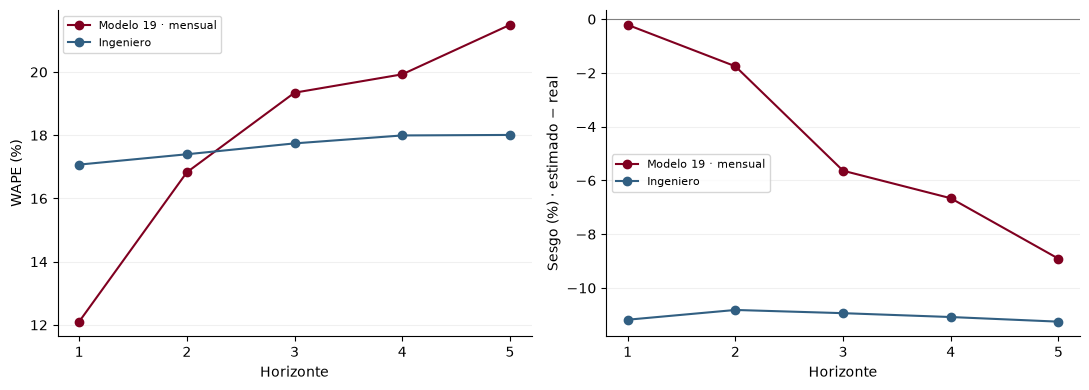

,periodo,horizonte,producto,casos,WAPE_modelo,WAPE_ingeniero,sesgo_modelo,sesgo_ingeniero
0,extension_desde_S37,1.0,AMAZON,6,30.895033,25.933202,17.484159,20.432220
1,extension_desde_S37,1.0,BARBATUS,30,26.298049,24.983477,4.669555,-15.554087
2,extension_desde_S37,1.0,CARNATION,231,16.368778,17.484595,-8.793490,-4.847105
3,extension_desde_S37,1.0,GREEN BALL,6,10.393622,14.983779,-5.472342,-10.563666
4,extension_desde_S37,1.0,MINICARNATION,183,10.243203,15.104617,2.630890,-13.129771
5,extension_desde_S37,1.0,RAFFINE,30,11.890387,29.466129,0.756003,-7.796956
6,extension_desde_S37,1.0,SOLOMIO,62,11.389275,18.652433,-1.786958,-16.727306
7,extension_desde_S37,1.0,STAR,6,27.001481,25.139915,21.332713,25.139915
8,extension_desde_S37,1.0,STATICE,28,28.607521,33.086185,10.317504,-27.203652
9,extension_desde_S37,1.0,VERONICA,12,35.143505,48.355664,15.550355,28.258222


In [7]:
plt.rcParams.update({'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False})
recent=metrics.loc[metrics.periodo.eq('extension_desde_S37')&metrics.comparacion.eq('19_mensual_sin_clima')&metrics.horizonte.ne('Total')]
fig,axes=plt.subplots(1,2,figsize=(11,4))
for method,label,color in [('19_mensual_sin_clima','Modelo 19 · mensual','#800020'),('Ingeniero','Ingeniero','#315f82')]:
    g=recent.loc[recent.metodo.eq(method)].sort_values('horizonte')
    axes[0].plot(g.horizonte,g.WAPE,'o-',label=label,color=color)
    axes[1].plot(g.horizonte,g.sesgo_pct,'o-',label=label,color=color)
axes[0].set(ylabel='WAPE (%)',xlabel='Horizonte');axes[1].set(ylabel='Sesgo (%) · estimado − real',xlabel='Horizonte')
axes[1].axhline(0,color='gray',linewidth=.8)
for ax in axes:ax.legend(fontsize=8);ax.grid(axis='y',alpha=.18)
fig.tight_layout();fig.savefig(OUT/'figuras/extension_horizontes.png',dpi=180);plt.show()
product=[]
for (period,h,prod),g in monthly.dropna(subset=['ingeniero']).groupby(['periodo','horizonte','producto']):
    product.append({'periodo':period,'horizonte':h,'producto':prod,'casos':len(g),
        'WAPE_modelo':score(g.y,g.prediccion)['WAPE'],'WAPE_ingeniero':score(g.y,g.ingeniero)['WAPE'],
        'sesgo_modelo':score(g.y,g.prediccion)['sesgo_pct'],'sesgo_ingeniero':score(g.y,g.ingeniero)['sesgo_pct']})
products=pd.DataFrame(product);products.to_csv(OUT/'errores_producto.csv',index=False)
display(products.loc[products.periodo.eq('extension_desde_S37')&products.horizonte.eq(1)])

## 7. Pronóstico con la información local más reciente

Se genera una simulación del origen del lunes correspondiente al corte de evaluación (26/10), usando únicamente variables anteriores a ese origen y el ajuste mensual correspondiente. No se pronostica desde un lunes futuro con días todavía desconocidos. La fecha real de cálculo se guarda aparte de ese corte; no se presenta como pronóstico anticipado publicado el 26/10. Sus objetivos no terminados no entran en las métricas anteriores.

In [8]:
latest_origin=AS_OF-pd.Timedelta(days=AS_OF.dayofweek)
future=df.loc[df.origen.eq(latest_origin)&df.admisible_modelo].copy()
assert len(future)
cut=df.loc[df.origen.dt.to_period('M').eq(latest_origin.to_period('M')),'origen'].min()
p,route=predict(train_at(cut),future)
proposal=future[KEY+['origen','semana_objetivo','horizonte']].copy()
proposal['prediccion']=p;proposal['ruta']=route;proposal['fecha_calculo']=pd.Timestamp.now(tz='UTC')
proposal['estado']='simulacion_retrospectiva_no_publicada'
proposal.to_parquet(OUT/'pronostico_mas_reciente.parquet',index=False)
totals=proposal.groupby(['horizonte','semana_objetivo']).prediccion.sum().reset_index()
totals.to_csv(OUT/'totales_pronostico_reciente.csv',index=False);display(totals)

,horizonte,semana_objetivo,prediccion
0,1.0,2026-10-26,1.417147e+06
1,2.0,2026-11-02,1.401547e+06
2,3.0,2026-11-09,1.390477e+06
3,4.0,2026-11-16,1.379759e+06
4,5.0,2026-11-23,1.369336e+06


## 8. Qué significa reentrenar «en vivo» y qué falta validar

Aquí **no** significa aprender de cada tallo en tiempo real: es un reentrenamiento por lotes al primer origen mensual. Cargar fuentes, entrenar, evaluar y publicar son acciones distintas. Dentro del mes se reutiliza el ajuste compatible con su corte y versión de datos; una versión nueva de las fuentes puede invalidar la caché. La empresa debe acordar cuándo se congela el corte y cómo se gestionan correcciones.

Operación propuesta: (1) validar y versionar fuentes; (2) calcular variables conocidas al corte; (3) reentrenar cuando corresponde; (4) comprobar esquema, finitud, coherencia de totales y comportamiento de validación; (5) conservar la versión anterior y revisar la candidata; (6) generar y guardar la propuesta antes de observar el objetivo; (7) publicar por decisión explícita; (8) al cerrar cada objetivo, calcular WAPE y sesgo por horizonte sobre casos comparables. Registrar origen, objetivo, fecha de emisión, corte train, versión y clima. Los cambios de parámetros se validan con ventanas anteriores; no se tunea con el período final que se usa para comunicar desempeño.

Una caída de rendimiento inicia una revisión de datos, mezcla de productos, sesgo y cambios operativos; no justifica reentrenar indefinidamente hasta ganar al ingeniero. Los umbrales empresariales de alerta y promoción siguen pendientes de acuerdo. El protocolo de publicación anticipada y la comparación con igual información del jueves requieren validación operativa.

Referencias metodológicas primarias: [Hyndman y Athanasopoulos, evaluación con origen móvil](https://otexts.com/fpp3/tscv.html); [scikit-learn, prevención de fuga](https://scikit-learn.org/stable/common_pitfalls.html); [Google Cloud, validación y operación de pipelines de ML](https://docs.cloud.google.com/architecture/mlops-continuous-delivery-and-automation-pipelines-in-machine-learning). No es necesario desplegar infraestructura adicional para justificar este protocolo.

In [9]:
recent_table=metrics.loc[metrics.periodo.eq('extension_desde_S37')&metrics.comparacion.eq('19_mensual_sin_clima')]
m=recent_table.loc[recent_table.metodo.eq('19_mensual_sin_clima')&recent_table.horizonte.eq('Total')].iloc[0]
e=recent_table.loc[recent_table.metodo.eq('Ingeniero')&recent_table.horizonte.eq('Total')].iloc[0]
print(f"Extensión pareada: {int(m.casos):,} casos; modelo WAPE {m.WAPE:.2f} %, ingeniero {e.WAPE:.2f} %.")
print(f"Sesgo: modelo {m.sesgo_pct:.2f} %, ingeniero {e.sesgo_pct:.2f} %.")
print('El resultado se informa tal como salió; no se reajustaron parámetros para mejorar esta tabla.')
print('Las diferencias con la prueba original no son una comparación experimental pura: se ampliaron datos y semanas.')
print('Pendientes: emisión anticipada con el mismo corte del ingeniero, disponibilidad histórica de fuentes y estabilidad en más temporadas.')
assert all(r['train_ultimo_cierre']<=r['corte'] for r in fit_controls)
assert not proposal.prediccion.isna().any()
(OUT/'verificacion_final.json').write_text(json.dumps({'passed':True,'cortes_sin_objetivos_futuros':True,
    'parametros_19_conservados':True,'imputacion_solo_train':True,'ingeniero_no_predictor':True,
    'reales_ausentes_no_imputados':True,'solo_semanas_cerradas_evaluadas':True,
    'propuestas_no_publicadas':True,'resumen':summary},ensure_ascii=False,indent=2),encoding='utf-8')

Extensión pareada: 3,399 casos; modelo WAPE 18.10 %, ingeniero 17.66 %.
Sesgo: modelo -4.76 %, ingeniero -11.05 %.
El resultado se informa tal como salió; no se reajustaron parámetros para mejorar esta tabla.
Las diferencias con la prueba original no son una comparación experimental pura: se ampliaron datos y semanas.
Pendientes: emisión anticipada con el mismo corte del ingeniero, disponibilidad histórica de fuentes y estabilidad en más temporadas.


927